# Unit 3, Exercise 2: simple linear regression

The module's cells are kept, with one fix marked below. Everything under **My changes** is mine.

*The comments at the end of the module's own code lines are mine, added to explain what each line does. The module's original comments are unchanged.*

> **Fix (mine):** the original cell imported `stats` but called `stat.linregress` and `stat.pearsonr`, so it stopped with `NameError: name 'stat' is not defined`. I changed `stat.` to `stats.` in both places.

Pearsons correlation: -0.759


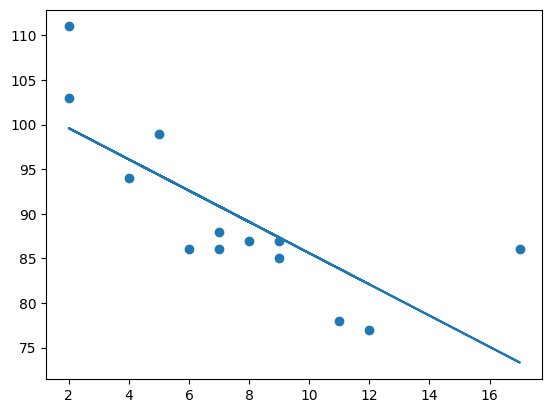

In [1]:
import matplotlib.pyplot as plt                     # plotting
from scipy import stats                             # statistics functions, including linear regression

#Create the arrays that represent the values of the x and y axis
x = [5,7,8,7,2,17,2,9,4,11,12,9,6]                  # car age in years (the input)
y = [99,86,87,88,111,86,103,87,94,78,77,85,86]      # car speed (the output)

#Execute a method that returns some important key values of Linear Regression
slope, intercept, r, p, std_err = stats.linregress(x, y)  # fit the best straight line through the points

# measure the correlation 
corr, _ = stats.pearsonr(x, y)                      # Pearson r between age and speed
print('Pearsons correlation: %.3f' % corr)          # how strong the straight-line link is

#Create a function that uses the slope and intercept values to return a new value. 
#This new value represents where on the y-axis the corresponding x value will be placed
def myfunc(x):                                      # the fitted line as a function
  return slope * x + intercept                      # y = slope times x plus intercept

#Run each value of the x array through the function. This will result in a new array with new values for the y-axis
mymodel = list(map(myfunc, x))                      # the line's value at every x

#Draw the original scatter plot & the line of linear regression
plt.scatter(x, y)                                   # the real data points
plt.plot(x, mymodel)                                # the fitted line on top
plt.show()                                          # draw the plot


## Predict Future Values

In [2]:
from scipy import stats                             # statistics functions, including linear regression

x = [5,7,8,7,2,17,2,9,4,11,12,9,6]                  # car age in years (the input)
y = [99,86,87,88,111,86,103,87,94,78,77,85,86]      # car speed (the output)

slope, intercept, r, p, std_err = stats.linregress(x, y)  # fit the best straight line through the points

def myfunc(x):                                      # the fitted line as a function
  return intercept + slope * x                      # same line, written the other way round

speed = myfunc(10)                                  # predict the speed of a 10-year-old car

print(speed)                                        # show the prediction

85.59308314937454


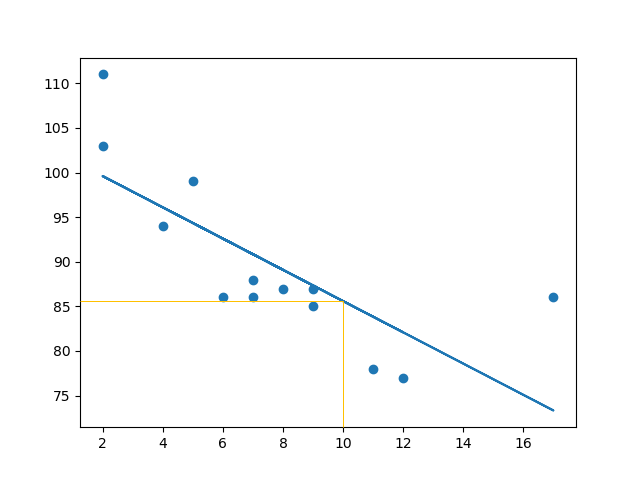

If x=10 then predicted y is 85.59

## My changes

### 1. Remove one point, add one point

original 13 points               slope= -1.75  intercept= 103.1  r=-0.76  prediction at x=10:  85.6
drop the x=17 point              slope= -2.88  intercept= 109.8  r=-0.93  prediction at x=10:  81.0
add one outlier at (15, 120)     slope= -0.61  intercept=  96.9  r=-0.22  prediction at x=10:  90.8


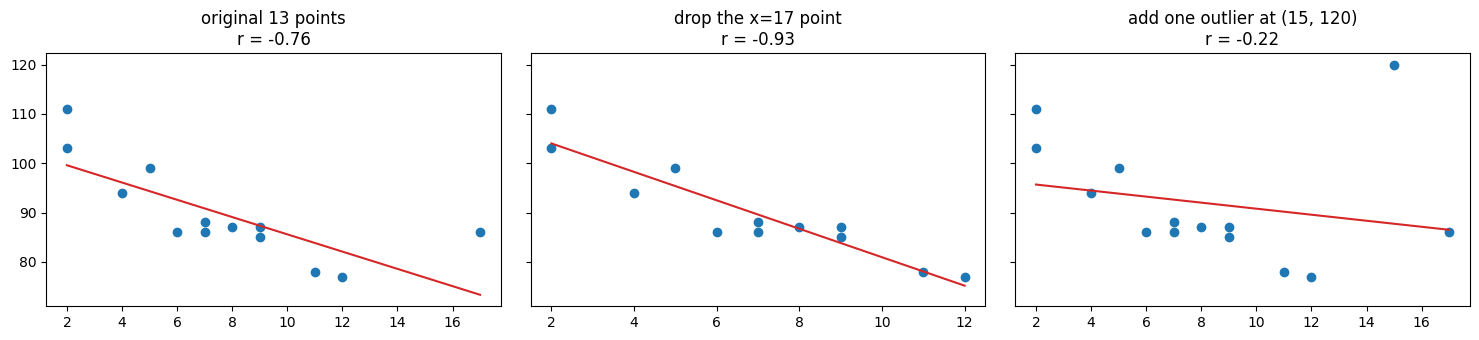

In [3]:
x0 = [5,7,8,7,2,17,2,9,4,11,12,9,6]                 # the module's original x values
y0 = [99,86,87,88,111,86,103,87,94,78,77,85,86]     # the module's original y values

def fit(x, y, label):                                # fit a straight line and print its key numbers
    res = stats.linregress(x, y)                     # slope, intercept and r for this set of points
    print(f"{label:<32} slope={res.slope:6.2f}  intercept={res.intercept:6.1f}  r={res.rvalue:5.2f}  "  # slope, intercept, r and a sample prediction
          f"prediction at x=10: {res.intercept + res.slope * 10:5.1f}")   # also show what it predicts at x = 10
    return res                                       # hand the fit back so it can be plotted

fits = {                                             # three versions of the data to compare
    "original 13 points": (x0, y0),                  # as supplied
    "drop the x=17 point": ([v for v in x0 if v != 17], [y for v, y in zip(x0, y0) if v != 17]),   # one point removed
    "add one outlier at (15, 120)": (x0 + [15], y0 + [120]),   # one extreme point added
}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)   # three plots side by side, same y scale
for ax, (label, (x, y)) in zip(axes, fits.items()):   # one plot per version of the data
    res = fit(x, y, label)                           # fit and print
    xs = sorted(x)                                   # sort x so the line is drawn left to right
    ax.scatter(x, y); ax.plot(xs, [res.intercept + res.slope * v for v in xs], color="tab:red")   # points and fitted line
    ax.set_title(f"{label}\nr = {res.rvalue:.2f}")   # title with the correlation
plt.tight_layout(); plt.show()                       # draw

### 2. Predicting outside the data

In [4]:
res = stats.linregress(x0, y0)                       # fit the original 13 points again
for x_new in [10, 17, 30, 60]:                       # two x values inside the data (2 to 17) and two far outside
    print(f"x={x_new:>3}  predicted y = {res.intercept + res.slope * x_new:6.1f}")   # the line's prediction

x= 10  predicted y =   85.6
x= 17  predicted y =   73.3
x= 30  predicted y =   50.6
x= 60  predicted y =   -2.0


## What I took from it


- **The supplied notebook didn't run.** It imported `stats` and called `stat`. A small thing, but it's the
  kind of error that's easy to miss when you copy code across. I fixed it and marked the fix.
- **One point was doing a lot of work.** Dropping the single point at x = 17 moved the slope from −1.75 to −2.88
  and the correlation from −0.76 to −0.93. That one point sits far to the right with a high y, so it drags
  the line flat. With only 13 points, each one carries a lot of weight.
- **One outlier can nearly erase the relationship.** Adding a single point at (15, 120) dropped r to −0.22.
- **A straight line has no idea where to stop.** At x = 60 the model predicts a value of −2. The data only
  runs from 2 to 17, so anything far outside that is a guess, not a prediction.